In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv('Melbourne_Housing_NoMissing.csv')
data.head()

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,Regionname,Propertycount,Price,Total_Space_New
0,Airport West,3,t,Nelson,2016-03-09,13.5,3042.0,3,2,1,303.0,Western Metropolitan,3464,840000,9
1,Albert Park,2,h,hockingstuart,2016-03-09,3.3,3206.0,2,1,0,120.0,Southern Metropolitan,3280,1275000,5
2,Albert Park,2,h,Thomson,2016-03-09,3.3,3206.0,2,1,0,159.0,Southern Metropolitan,3280,1455000,5
3,Alphington,4,h,Brace,2016-03-09,6.4,3078.0,3,2,4,853.0,Northern Metropolitan,2211,2000000,13
4,Alphington,3,h,Jellis,2016-03-09,6.4,3078.0,3,2,2,208.0,Northern Metropolitan,2211,1110000,10


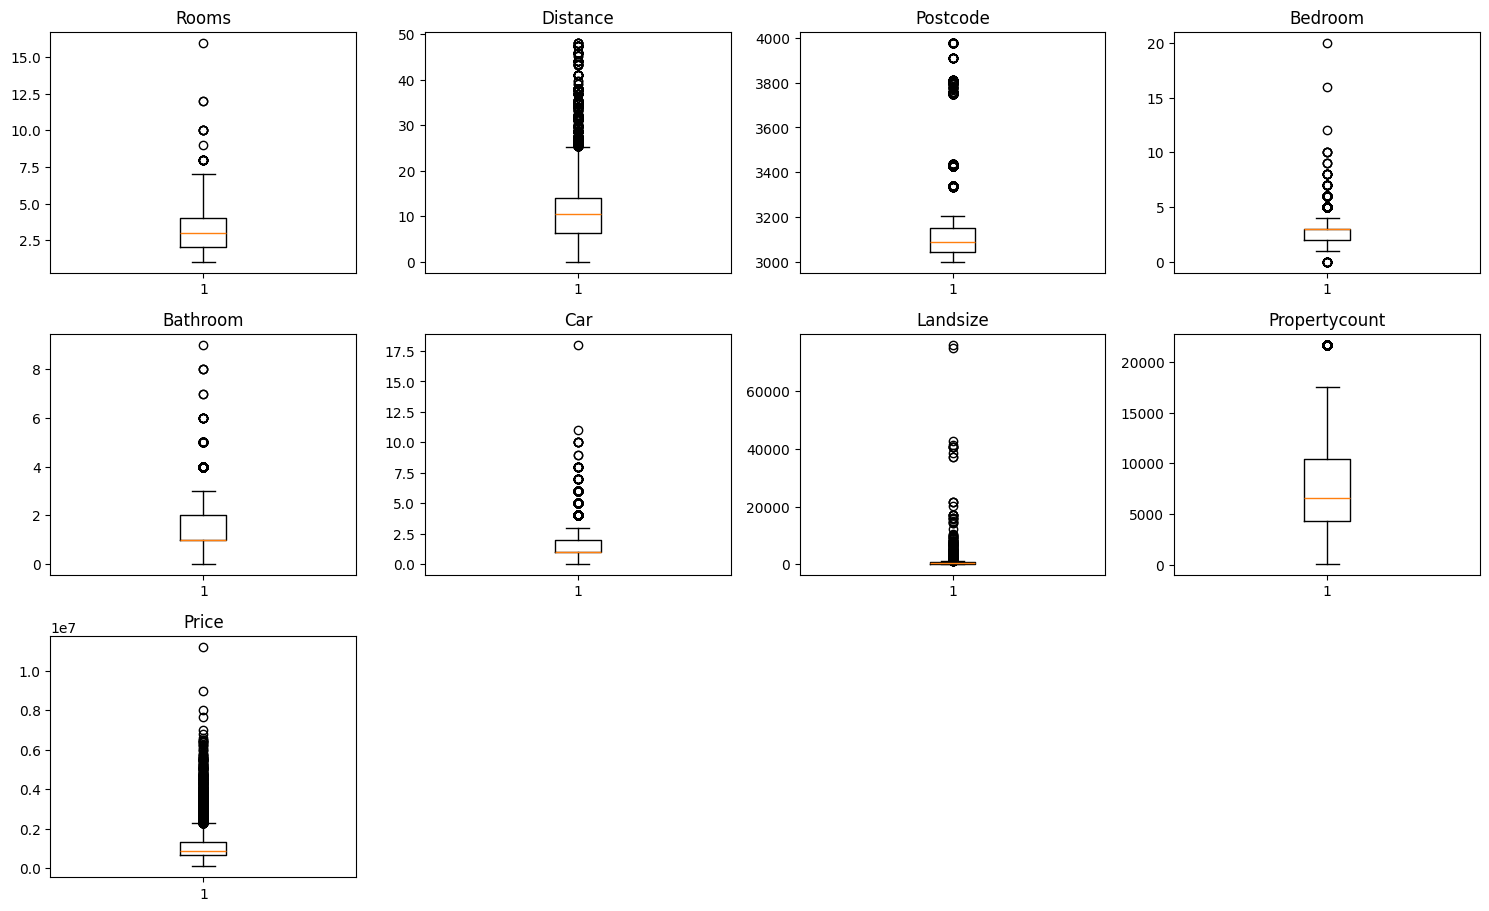

In [4]:
# selecting the numerical columns of data and adding therir names in a list 
numeric_columns = ['Rooms','Distance','Postcode','Bedroom','Bathroom','Car','Landsize','Propertycount','Price']
plt.figure(figsize=(15,12))
for i,variable in enumerate(numeric_columns):
    plt.subplot(4,4,i+1) # 4 row 4 col
    plt.boxplot(data[variable],whis=1.5) #range of oulier detection
    plt.tight_layout()
    plt.title(variable)
plt.show()

Let's analyze each column to see if the values in them can be considered as outliers or not

* Rooms,Bedroom,Bathroom,Car The values which are being represented as outlier in the above boxplot may not seem realistic in some case.For example- it is not common to have more than 15 rooms,15 bedrooms,and more than 10 car parking spaces in a general scenario.

* Distance - The outliers in this column ca be considered as genuine values because a property can be at varying distance


In [5]:
Q1 = data[numeric_columns].quantile(0.25)
Q3 = data[numeric_columns].quantile(0.75)
IQR = Q3 - Q1 
lower_whisker = Q1-1.5*IQR
upper_whisker = Q3+1.5*IQR

In [8]:
# Outliers Percentage for each column 
((data[numeric_columns]<lower_whisker) | (data[numeric_columns]>upper_whisker)).sum()/data.shape[0]*100

Rooms            0.084865
Distance         4.342853
Postcode         2.911224
Bedroom          4.195262
Bathroom         0.870784
Car              4.305955
Landsize         1.741569
Propertycount    2.671390
Price            4.660173
dtype: float64

In [9]:
def treat_outliers(df,col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR
    df[col] = np.clip(df[col],lower_whisker,upper_whisker)
    return df

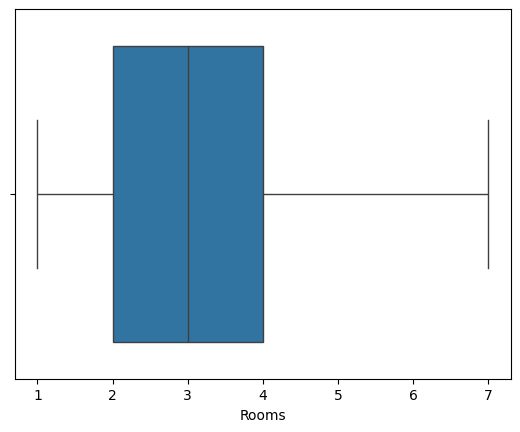

In [10]:
data = treat_outliers(data,'Rooms')
sns.boxplot(data=data,x='Rooms')
plt.show()